## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Miguel Labra Lorenzana

* **Matrícula:** A01363726



**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [1]:
import os, re, json, urllib.request, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

pd.set_option('display.max_colwidth', 60)
np.random.seed(42)

# Descarga de MovieLens 1M (solo si no está ya en la carpeta)
if not os.path.exists('ml-1m/ratings.dat'):
    urllib.request.urlretrieve('https://files.grouplens.org/datasets/movielens/ml-1m.zip', 'ml-1m.zip')
    zipfile.ZipFile('ml-1m.zip').extractall('.')
print('Datos listos')

Datos listos


# **Ejercicio - 1: cargando datos**

In [2]:
ratings = pd.read_csv('ml-1m/ratings.dat', sep='::', engine='python',
                      names=['user_id', 'movie_id', 'rating', 'timestamp'])
movies  = pd.read_csv('ml-1m/movies.dat', sep='::', engine='python',
                      names=['movie_id', 'title', 'genres'], encoding='latin-1')
users   = pd.read_csv('ml-1m/users.dat', sep='::', engine='python',
                      names=['user_id', 'gender', 'age', 'occupation', 'zip'])

print('Usuarios:', ratings.user_id.nunique())
print('Películas en movies.dat:', len(movies), '| películas con al menos una evaluación:', ratings.movie_id.nunique())
print('Evaluaciones:', len(ratings))
print('Escala de evaluación:', sorted(ratings.rating.unique().tolist()))
display(ratings.head(3), movies.head(3), users.head(3))

Usuarios: 6040
Películas en movies.dat: 3883 | películas con al menos una evaluación: 3706
Evaluaciones: 1000209
Escala de evaluación: [1, 2, 3, 4, 5]


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,user_id,gender,age,occupation,zip
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


**Respuestas:**

a. Hay **6,040 usuarios**, **3,883 películas** en el catálogo (de las cuales **3,706** tienen al menos una evaluación) y **1,000,209 evaluaciones**.

b. Las películas se califican con números enteros del **1 al 5** (estrellas).

# **Ejercicio - 2: matriz de utilidad**

In [3]:
# Índices consecutivos para usuarios y películas
user_ids  = np.sort(ratings.user_id.unique())
movie_ids = np.sort(ratings.movie_id.unique())
ratings['u'] = np.searchsorted(user_ids, ratings.user_id)
ratings['m'] = np.searchsorted(movie_ids, ratings.movie_id)

# Matriz de utilidad: filas = usuarios, columnas = películas (formato disperso)
R = csr_matrix((ratings.rating, (ratings.u, ratings.m)), shape=(len(user_ids), len(movie_ids)))

densidad = R.nnz / (R.shape[0] * R.shape[1])
print('Dimensión de la matriz de utilidad:', R.shape)
print(f'Densidad: {densidad:.4f} ({densidad:.2%})')
print(f'Dispersión (sparsity): {1 - densidad:.4f} ({1 - densidad:.2%})')

Dimensión de la matriz de utilidad: (6040, 3706)
Densidad: 0.0447 (4.47%)
Dispersión (sparsity): 0.9553 (95.53%)


**Respuestas:**

a. La matriz de utilidad (usuarios × películas) es de **6,040 × 3,706**. Su densidad es de apenas **4.47%**, es decir, una dispersión de **95.53%**.

b. Más del 95% de las celdas están vacías: cada usuario solo ha visto una pequeña fracción del catálogo (en promedio unas 165 películas de 3,706). Precisamente el trabajo del sistema de recomendación es "llenar" esos huecos estimando qué le gustaría a cada usuario.

c. Consideraciones al trabajar con matrices tan dispersas:
* **Memoria:** conviene guardarlas en formato disperso (por ejemplo `csr_matrix`), que solo almacena los valores existentes.
* **Valores faltantes ≠ cero:** un hueco significa "no lo ha visto", no "le dio 0". Por eso se centran las calificaciones con el promedio de cada usuario antes de factorizar.
* **Algoritmos adecuados:** usar SVD truncado (`svds`, `TruncatedSVD`) que trabaja directo sobre la matriz dispersa y calcula solo las primeras *k* componentes.
* **Arranque en frío:** usuarios o películas con muy pocas evaluaciones dan estimaciones poco confiables.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

80% de varianza -> 709 componentes
90% de varianza -> 1082 componentes
95% de varianza -> 1440 componentes


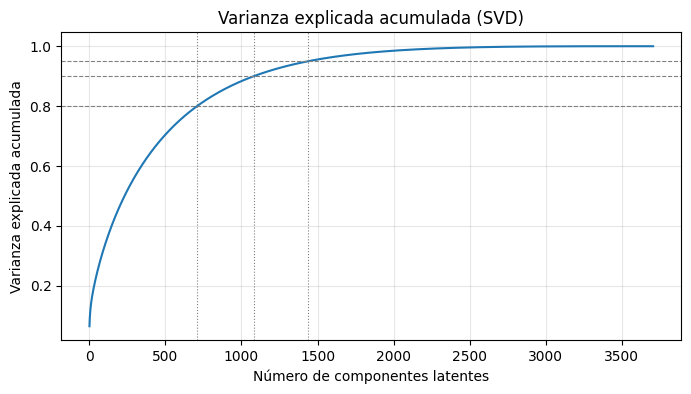

In [4]:
# Centramos cada calificación restando el promedio del usuario (los huecos quedan en 0 = "neutral")
media_usuario = ratings.groupby('u').rating.mean()
ratings['r_c'] = ratings.rating - media_usuario[ratings.u].values
R_c = csr_matrix((ratings.r_c, (ratings.u, ratings.m)), shape=R.shape)

# Valores singulares de toda la matriz para medir la varianza explicada acumulada
s_all = np.linalg.svd(R_c.toarray(), compute_uv=False)
var_acum = np.cumsum(s_all**2) / np.sum(s_all**2)

comp = {p: int(np.argmax(var_acum >= p) + 1) for p in [0.80, 0.90, 0.95]}
for p, k in comp.items():
    print(f'{int(p*100)}% de varianza -> {k} componentes')

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(var_acum) + 1), var_acum)
for p, k in comp.items():
    plt.axhline(p, ls='--', lw=0.8, c='gray'); plt.axvline(k, ls=':', lw=0.8, c='gray')
plt.xlabel('Número de componentes latentes'); plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada (SVD)'); plt.grid(alpha=0.3); plt.show()

**Respuestas:**

b. Se necesitan **709 componentes** para el 80% de la varianza, **1,082** para el 90% y **1,440** para el 95%.

c. La curva crece muy despacio: no hay un "codo" claro y para explicar mucha varianza hay que quedarse con cientos de componentes, casi la mitad del total de películas. Gran parte de esa varianza es "ruido" (gustos muy particulares de cada persona), así que este criterio por sí solo sugeriría un número muy alto (alrededor de **700**, para el 80%) que no es práctico ni necesariamente mejor para recomendar. Por eso conviene contrastarlo con el RMSE en el siguiente ejercicio.

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**



RMSE de referencia (solo promedio del usuario): 1.0344


,0,1,2,3,4,5,6,7,8,9,10
k,2.0000,5.0000,10.0000,15.0000,20.0000,30.000,50.0000,75.0000,100.0000,150.0000,200.0000
RMSE,0.9841,0.9725,0.9628,0.9593,0.9579,0.958,0.9624,0.9686,0.9743,0.9841,0.9921


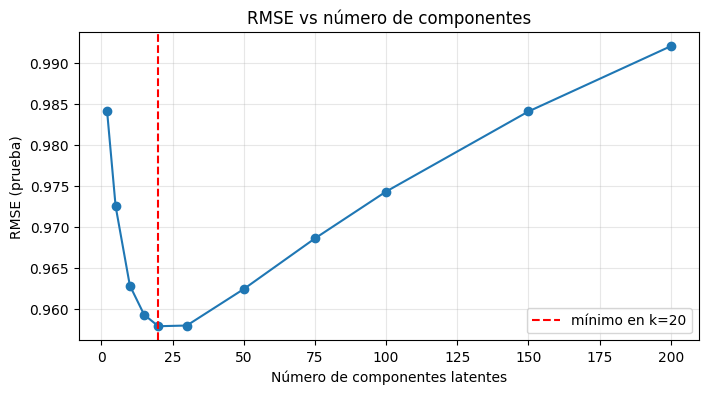

In [5]:
# a. División 80% entrenamiento / 20% prueba
idx = np.random.default_rng(42).permutation(len(ratings))
n_tr = int(0.8 * len(ratings))
train, test = ratings.iloc[idx[:n_tr]], ratings.iloc[idx[n_tr:]]

media_tr = train.groupby('u').rating.mean()
R_tr = csr_matrix((train.rating - media_tr[train.u].values, (train.u, train.m)), shape=R.shape)
base_test = test.u.map(media_tr).fillna(train.rating.mean()).values

def rmse_svd(k):
    U, S, Vt = svds(R_tr, k=k)
    pred = np.sum(U[test.u] * S * Vt.T[test.m], axis=1) + base_test
    pred = np.clip(pred, 1, 5)
    return np.sqrt(np.mean((test.rating.values - pred) ** 2))

print('RMSE de referencia (solo promedio del usuario):', round(np.sqrt(np.mean((test.rating.values - base_test) ** 2)), 4))

# b y c. RMSE para distintos números de componentes
ks = [2, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200]
rmses = [rmse_svd(k) for k in ks]
tabla_rmse = pd.DataFrame({'k': ks, 'RMSE': np.round(rmses, 4)})
display(tabla_rmse.T)

plt.figure(figsize=(8, 4))
plt.plot(ks, rmses, marker='o')
k_best = ks[int(np.argmin(rmses))]
plt.axvline(k_best, ls='--', c='red', label=f'mínimo en k={k_best}')
plt.xlabel('Número de componentes latentes'); plt.ylabel('RMSE (prueba)')
plt.title('RMSE vs número de componentes'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Respuestas:**

b. El modelo se entrena con el 80% de las evaluaciones y se mide sobre el 20% restante. Como referencia, predecir solo con el promedio de cada usuario da un RMSE ≈ 1.03; con SVD baja hasta **≈ 0.958**.

d. El RMSE baja rápido hasta unas **20 componentes** y después vuelve a subir: con más componentes el modelo empieza a memorizar ruido del entrenamiento (sobreajuste). Entre 20 y 30 la diferencia es mínima, así que elijo **k = 20**: es el error más bajo con el modelo más sencillo.

# **Ejercicio - 5: comparación varianza explicada vs RMSE**

In [6]:
k_sel = 20
print(f'Varianza explicada con k={k_sel}: {var_acum[k_sel-1]:.2%}')
print(f'RMSE con k={k_sel}: {tabla_rmse.set_index("k").loc[k_sel, "RMSE"]}')
print(f'Componentes para 80% de varianza: {comp[0.80]} -> RMSE aprox. con k=200: {tabla_rmse.set_index("k").loc[200, "RMSE"]} (y peor al crecer)')

Varianza explicada con k=20: 16.87%
RMSE con k=20: 0.9579
Componentes para 80% de varianza: 709 -> RMSE aprox. con k=200: 0.9921 (y peor al crecer)


**Comparación:**

| Criterio | Componentes sugeridas | Observación |
|---|---|---|
| Varianza explicada (80%) | ~709 | Busca reconstruir la matriz completa, incluido el ruido. |
| RMSE en prueba | ~20 | Busca predecir bien calificaciones nuevas. |

Con 20 componentes solo se explica ~17% de la varianza, pero es justo lo que mejor predice: esas primeras componentes capturan los patrones generales de gusto (acción vs. drama, cine clásico vs. reciente, etc.) y el resto es en gran parte ruido. Como el objetivo es **recomendar** (predecir gustos) y no reconstruir la matriz, me quedo con el criterio del RMSE: **k = 20** para el resto de la actividad. Además es un modelo más ligero y rápido.

# **Ejercicio - 6: sistema de recomendación colaborativo**

In [7]:
# SVD final con k=20 sobre todos los datos (matriz centrada)
U, S, Vt = svds(R_c, k=k_sel)
lat_peliculas = Vt.T * S          # cada película representada por 20 factores latentes

# a y b. Matriz de similitud del coseno entre películas
sim_svd = cosine_similarity(lat_peliculas)
print('Dimensión de la matriz de similitud:', sim_svd.shape)

# Catálogo alineado con los índices de la matriz
cat = movies.set_index('movie_id').loc[movie_ids].reset_index()
cat['n_ratings'] = ratings.groupby('m').size().values
cat['rating_prom'] = ratings.groupby('m').rating.mean().round(2).values

def idx_pelicula(titulo):
    return int(cat.index[cat.title == titulo][0])

def recomendar(titulo, sim, n=10):
    i = idx_pelicula(titulo)
    orden = np.argsort(-sim[i]); orden = orden[orden != i][:n]
    res = cat.loc[orden, ['title', 'genres', 'n_ratings']].copy()
    res['similitud'] = sim[i, orden].round(3)
    return res.reset_index(drop=True).rename(lambda x: x + 1)

pelicula = 'Matrix, The (1999)'
rec_svd = recomendar(pelicula, sim_svd)
print(f'\nTop 10 recomendaciones (SVD) para: {pelicula}')
display(rec_svd)

Dimensión de la matriz de similitud: (3706, 3706)

Top 10 recomendaciones (SVD) para: Matrix, The (1999)


,title,genres,n_ratings,similitud
1,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,2649,0.805
2,"Terminator, The (1984)",Action|Sci-Fi|Thriller,2098,0.753
3,"Professional, The (a.k.a. Leon: The Professional) (1994)",Crime|Drama|Romance|Thriller,923,0.747
4,"Sixth Sense, The (1999)",Thriller,2459,0.742
5,Gladiator (2000),Action|Drama,1924,0.735
6,Aliens (1986),Action|Sci-Fi|Thriller|War,1820,0.733
7,Twelve Monkeys (1995),Drama|Sci-Fi,1511,0.725
8,X-Men (2000),Action|Sci-Fi,1511,0.717
9,Better Living Through Circuitry (1999),Documentary,16,0.706
10,Blade Runner (1982),Film-Noir|Sci-Fi,1800,0.699


**Respuestas:**

b. La matriz de similitud es de **3,706 × 3,706** (cada película comparada con todas las demás).

c. Película elegida: **The Matrix (1999)**. Las 10 recomendaciones y su similitud aparecen en la tabla anterior.

d. Sí, son bastante coherentes: aparecen *Terminator 2*, *Terminator*, *Aliens*, *Twelve Monkeys*, *Blade Runner* y *X-Men*, todas de ciencia ficción/acción, y otras muy populares entre el mismo público (*Gladiator*, *The Professional*, *The Sixth Sense*). Lo curioso es *Better Living Through Circuitry*, un documental poco conocido: con pocas evaluaciones (unas cuantas personas que también vieron Matrix) el modelo puede encontrar similitudes "accidentales". Es una limitación típica del filtrado colaborativo.

e. **Explicación para no expertos:** el sistema no "sabe" de qué trata cada película; solo mira **quién vio qué y cómo lo calificó**. A partir de un millón de calificaciones descubre unos pocos "gustos ocultos" (por ejemplo, "le gusta la acción futurista" o "prefiere dramas clásicos") y describe cada película según qué tanto tiene de cada uno. Si dos películas tienen un perfil parecido —porque le gustan a las mismas personas— se recomiendan entre sí. Es como el "a quienes les gustó esto también les gustó…" de una tienda.

# **Ejercicio - 7: sistema de recomendación híbrido**

In [8]:
# a. Año de lanzamiento -> década
cat['anio'] = cat.title.str.extract(r'\((\d{4})\)\s*$').astype(int)
cat['decada'] = (cat.anio // 10 * 10).astype(str) + 's'
X_dec = pd.get_dummies(cat.decada, prefix='dec').astype(float)

# b. Géneros (una película puede tener varios)
X_gen = cat.genres.str.get_dummies(sep='|').astype(float)

# b. Factores de users.dat agregados por película: perfil del público que la evalúa
r_u = ratings.merge(users, on='user_id')
r_u['mujer'] = (r_u.gender == 'F').astype(float)
r_u['joven'] = (r_u.age < 25).astype(float)                       # menores de 25
r_u['adulto'] = r_u.age.between(25, 44).astype(float)              # 25 a 44
r_u['mayor'] = (r_u.age >= 45).astype(float)                       # 45 o más
X_pub = r_u.groupby('m')[['mujer', 'joven', 'adulto', 'mayor']].mean()
X_pub.columns = ['pct_mujeres', 'pct_jovenes', 'pct_adultos', 'pct_mayores']
X_pub_z = (X_pub - X_pub.mean()) / X_pub.std()                      # estandarizar

# c. Matriz híbrida: cada bloque normalizado y con un peso
pesos = {'latentes': 1.0, 'genero': 0.6, 'decada': 0.4, 'publico': 0.4}
bloques = [
    pesos['latentes'] * normalize(lat_peliculas),
    pesos['genero']   * normalize(X_gen.values),
    pesos['decada']   * X_dec.values,
    pesos['publico']  * normalize(X_pub_z.values),
]
H = np.hstack(bloques)
print('Dimensión de la matriz híbrida:', H.shape,
      f'= {lat_peliculas.shape[1]} latentes + {X_gen.shape[1]} géneros + {X_dec.shape[1]} décadas + {X_pub.shape[1]} perfil de público')

sim_hib = cosine_similarity(H)

# e. Tabla comparativa para la misma película
rec_hib = recomendar(pelicula, sim_hib)
comparativa = pd.DataFrame({
    'SVD': rec_svd.title, 'sim SVD': rec_svd.similitud,
    'Híbrido': rec_hib.title, 'sim Híbrido': rec_hib.similitud})
print(f'\nComparativa de recomendaciones para: {pelicula}')
display(comparativa)

Dimensión de la matriz híbrida: (3706, 52) = 20 latentes + 18 géneros + 10 décadas + 4 perfil de público

Comparativa de recomendaciones para: Matrix, The (1999)


,SVD,sim SVD,Híbrido,sim Híbrido
1,Terminator 2: Judgment Day (1991),0.805,Terminator 2: Judgment Day (1991),0.875
2,"Terminator, The (1984)",0.753,"Fugitive, The (1993)",0.740
3,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.747,"Terminator, The (1984)",0.739
4,"Sixth Sense, The (1999)",0.742,"Sixth Sense, The (1999)",0.728
5,Gladiator (2000),0.735,Twelve Monkeys (1995),0.701
6,Aliens (1986),0.733,X-Men (2000),0.694
7,Twelve Monkeys (1995),0.725,Dark City (1998),0.693
8,X-Men (2000),0.717,"Hunt for Red October, The (1990)",0.692
9,Better Living Through Circuitry (1999),0.706,Total Recall (1990),0.692
10,Blade Runner (1982),0.699,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.692


**Respuestas:**

a. Del título se extrae el año y se convierte en **década** (1910s … 2000s), codificada con variables 0/1. Así películas de años cercanos se consideran parecidas sin dar demasiado peso al año exacto.

b. Factores elegidos:
* **Género:** variables 0/1 por cada uno de los 18 géneros (una película puede tener varios). Es la característica más directa del contenido.
* **Género del público (users.dat):** porcentaje de mujeres que califican la película.
* **Edad del público (users.dat):** la edad viene en rangos, así que la agrupé en tres: jóvenes (<25), adultos (25-44) y mayores (45+), y calculo el porcentaje de cada grupo por película.

Como estos datos son de usuarios y no de películas, se **agregan por película** para describir "qué tipo de público la ve". Se estandarizan para que estén en la misma escala.

c. La matriz híbrida tiene **3,706 filas** y las columnas resultantes de 20 factores latentes + 18 géneros + décadas + 4 de perfil de público (ver dimensión exacta impresa arriba). Cada bloque se normaliza y se pondera (latentes 1.0, género 0.6, década 0.4, público 0.4) para que ninguno domine.

d. Beneficios frente a solo SVD:
* Las recomendaciones respetan más el **tipo de película** (género, época), no solo coincidencias de audiencia.
* Ayuda con películas con **pocas evaluaciones**, donde los factores latentes son poco confiables.
* Es más **explicable**: se puede decir "te la recomiendo porque también es de ciencia ficción de los 90".

f. **Comentarios:** ambas listas se parecen (comparten varias películas de ciencia ficción/acción), pero la híbrida se concentra más en el mismo género y época y saca títulos "accidentales" como el documental. A cambio, el modelo híbrido puede ser algo más predecible y menos sorpresivo. Las similitudes del híbrido no se comparan directamente con las de SVD porque se calculan en espacios distintos; lo que importa es el orden.

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

In [9]:
# a. El usuario indica sus 5 películas favoritas
favoritas = ['Matrix, The (1999)', 'Terminator 2: Judgment Day (1991)',
             'Star Wars: Episode IV - A New Hope (1977)', 'Alien (1979)', 'Blade Runner (1982)']

MIN_RATINGS = 50   # evitamos títulos con muy pocas evaluaciones (similitudes poco confiables)

def recomendar_perfil(favs, sim, n=10):
    idxs = [idx_pelicula(t) for t in favs]
    score = sim[idxs].mean(axis=0)                       # similitud promedio con las 5 favoritas
    score[idxs] = -np.inf
    score[cat.n_ratings.values < MIN_RATINGS] = -np.inf
    orden = np.argsort(-score)[:n]
    res = cat.loc[orden, ['title', 'genres', 'anio', 'n_ratings', 'rating_prom']].copy()
    res['similitud'] = score[orden].round(3)
    return res.reset_index(drop=True).rename(lambda x: x + 1)

def tabla_candidatas(favs):
    a, b = recomendar_perfil(favs, sim_svd), recomendar_perfil(favs, sim_hib)
    comp = pd.DataFrame({'SVD': a.title, 'sim SVD': a.similitud,
                         'Híbrido': b.title, 'sim Híbrido': b.similitud})
    return a, b, comp

top_svd, top_hib, comp8 = tabla_candidatas(favoritas)
print('Favoritas del usuario:', favoritas)
display(comp8)

Favoritas del usuario: ['Matrix, The (1999)', 'Terminator 2: Judgment Day (1991)', 'Star Wars: Episode IV - A New Hope (1977)', 'Alien (1979)', 'Blade Runner (1982)']


,SVD,sim SVD,Híbrido,sim Híbrido
1,"Terminator, The (1984)",0.794,"Terminator, The (1984)",0.744
2,Aliens (1986),0.793,Aliens (1986),0.720
3,Raiders of the Lost Ark (1981),0.706,Star Wars: Episode V - The Empire Strikes Back (1980),0.621
4,Star Wars: Episode V - The Empire Strikes Back (1980),0.693,Raiders of the Lost Ark (1981),0.604
5,Close Encounters of the Third Kind (1977),0.648,Die Hard (1988),0.591
6,Die Hard (1988),0.623,Star Trek: The Wrath of Khan (1982),0.581
7,Nikita (La Femme Nikita) (1990),0.616,Close Encounters of the Third Kind (1977),0.567
8,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.608,"Fugitive, The (1993)",0.567
9,Twelve Monkeys (1995),0.587,Predator (1987),0.565
10,Star Trek: The Wrath of Khan (1982),0.585,Dark City (1998),0.561


**Diseño del agente**

El agente funciona en tres pasos:
1. **Herramientas (recuperación):** calcula las 10 mejores candidatas con SVD y con el híbrido (tabla anterior), junto con su género, año, popularidad y calificación promedio.
2. **Razonamiento (LLM):** el modelo recibe esa información y elige las 5 finales, justificando cada una en relación con las favoritas del usuario.
3. **Validación:** se revisa automáticamente que las 5 películas existan en la lista de candidatas, para detectar alucinaciones.

**Modelo LLM utilizado:** Gemini 3.8 Flash de Google (`gemini-3.8-flash`), a través de su API, con otros modelos Gemini Flash como respaldo si el principal está saturado. El modelo que generó cada respuesta se imprime en la salida.

In [10]:
!pip install -q google-genai
import time
from google import genai
from google.colab import userdata

MODELO_LLM = 'gemini-3.8-flash'
cliente = genai.Client(api_key=userdata.get('agent'))

# Modelos de respaldo: otros modelos "flash" disponibles en tu cuenta, por si el principal está saturado
try:
    respaldo = [m.name.replace('models/', '') for m in cliente.models.list() if 'flash' in m.name]
except Exception:
    respaldo = []
MODELOS = [MODELO_LLM] + [m for m in respaldo if m != MODELO_LLM]
print('Modelos que se intentarán (en orden):', MODELOS[:5])

def llamar_llm(prompt_sistema, prompt_usuario, intentos_por_modelo=3):
    for modelo in MODELOS[:5]:
        espera = 5
        for i in range(intentos_por_modelo):
            try:
                resp = cliente.models.generate_content(
                    model=modelo,
                    contents=prompt_usuario,
                    config={'system_instruction': prompt_sistema})
                print(f'(respuesta generada con {modelo})')
                return resp.text
            except Exception as e:
                saturado = any(c in str(e) for c in ['503', '429', 'UNAVAILABLE', 'RESOURCE_EXHAUSTED'])
                no_existe = '404' in str(e) or 'NOT_FOUND' in str(e)
                if no_existe:
                    break                                   # ese modelo no sirve, pasar al siguiente
                if not saturado:
                    raise                                   # otro tipo de error: mostrarlo
                print(f'{modelo} ocupado, reintentando en {espera} s...')
                time.sleep(espera)
                espera *= 2
        print(f'{modelo} no respondió, probando con el siguiente modelo...')
    raise RuntimeError('Todos los modelos están saturados. Espera unos minutos y vuelve a ejecutar.')

Modelos que se intentarán (en orden): ['gemini-3.8-flash', 'gemini-2.5-flash', 'gemini-2.5-flash-preview-tts', 'gemini-flash-latest', 'gemini-flash-lite-latest']


In [11]:
PROMPT_SISTEMA = """Eres un agente experto en cine con el trasfondo de Christopher Nolan, Martin Scorsese y Quentin Tarantino que trabaja para una plataforma de streaming.
Tu tarea es elegir 5 películas para recomendar a un usuario, usando ÚNICAMENTE la lista de
candidatas que te entrega el sistema de recomendación. Reglas:
1. Solo puedes elegir títulos que aparezcan EXACTAMENTE en la lista de candidatas. No inventes películas.
2. No recomiendes ninguna de las películas favoritas del usuario.
3. Busca un balance: prioriza alta similitud, pero procura variedad y considera la calificación promedio.
4. Da preferencia a películas que aparezcan en ambos métodos (SVD e híbrido).
5. Justifica cada recomendación en 1 o 2 frases, relacionándola con las favoritas del usuario
   (género, época, estilo, tipo de público). Usa solo los datos proporcionados.
6. Responde SOLO con un JSON válido con este formato:
{"recomendaciones": [{"titulo": "...", "metodo": "SVD|Híbrido|Ambos", "justificacion": "..."}],
 "resumen": "una frase sobre el perfil del usuario"}"""

def construir_prompt(favs, top_svd, top_hib):
    cols = ['title', 'genres', 'anio', 'rating_prom', 'similitud']
    return f"""Películas favoritas del usuario:
{chr(10).join('- ' + f for f in favs)}

Candidatas según filtrado colaborativo (SVD):
{top_svd[cols].to_string()}

Candidatas según sistema híbrido (SVD + género + década + perfil de público):
{top_hib[cols].to_string()}

Elige las 5 mejores recomendaciones finales para este usuario."""

def agente_recomendador(favs, mostrar=True):
    top_svd, top_hib, comp = tabla_candidatas(favs)
    prompt = construir_prompt(favs, top_svd, top_hib)
    texto = llamar_llm(PROMPT_SISTEMA, prompt)
    datos = json.loads(texto[texto.find('{'): texto.rfind('}') + 1])
    recs = pd.DataFrame(datos['recomendaciones'])
    # Validación: ¿el título existe entre las candidatas? (detección de alucinaciones)
    candidatas = set(top_svd.title) | set(top_hib.title)
    recs['en_candidatas'] = recs.titulo.isin(candidatas)
    recs['es_favorita'] = recs.titulo.isin(favs)
    if mostrar:
        print('Perfil detectado:', datos.get('resumen', ''))
        display(recs)
    return recs, prompt

print('PROMPT DEL SISTEMA:\n', PROMPT_SISTEMA)
print('\nPROMPT DEL USUARIO:\n', construir_prompt(favoritas, top_svd, top_hib))

PROMPT DEL SISTEMA:
 Eres un agente experto en cine con el trasfondo de Christopher Nolan, Martin Scorsese y Quentin Tarantino que trabaja para una plataforma de streaming.
Tu tarea es elegir 5 películas para recomendar a un usuario, usando ÚNICAMENTE la lista de
candidatas que te entrega el sistema de recomendación. Reglas:
1. Solo puedes elegir títulos que aparezcan EXACTAMENTE en la lista de candidatas. No inventes películas.
2. No recomiendes ninguna de las películas favoritas del usuario.
3. Busca un balance: prioriza alta similitud, pero procura variedad y considera la calificación promedio.
4. Da preferencia a películas que aparezcan en ambos métodos (SVD e híbrido).
5. Justifica cada recomendación en 1 o 2 frases, relacionándola con las favoritas del usuario
   (género, época, estilo, tipo de público). Usa solo los datos proporcionados.
6. Responde SOLO con un JSON válido con este formato:
{"recomendaciones": [{"titulo": "...", "metodo": "SVD|Híbrido|Ambos", "justificacion": ".

In [12]:
# b y c. Recomendación final de 5 películas con justificación
recs8, _ = agente_recomendador(favoritas)

(respuesta generada con gemini-3.8-flash)
Perfil detectado: El usuario es un apasionado de los clásicos imperecederos de la ciencia ficción, la acción y las distopías de alto calibre narrativo estrenadas entre finales de los 70 y los 90.


,titulo,metodo,justificacion,en_candidatas,es_favorita
0,"Terminator, The (1984)",Ambos,Precuela directa de Terminator 2 que comparte la tensión...,True,False
1,Aliens (1986),Ambos,Secuela obligatoria de Alien que eleva la escala hacia l...,True,False
2,Star Wars: Episode V - The Empire Strikes Back (1980),Ambos,Continuación natural de Episode IV con un tono más sombr...,True,False
3,Raiders of the Lost Ark (1981),Ambos,Aporta dinamismo y variedad compartiendo la misma época ...,True,False
4,Close Encounters of the Third Kind (1977),Ambos,"Contemporánea de Star Wars y Alien, ofrece una mirada ci...",True,False


# **Ejercicio - 9: Evaluación del agente**

In [13]:
# Tres perfiles de usuario con gustos distintos
perfiles = {
    'Ciencia ficción / acción': favoritas,
    'Animación / familiar': ['Toy Story (1995)', 'Lion King, The (1994)', 'Aladdin (1992)',
                             'Beauty and the Beast (1991)', 'Little Mermaid, The (1989)'],
    'Drama / crimen': ['Godfather, The (1972)', 'Pulp Fiction (1994)', 'GoodFellas (1990)',
                       'Shawshank Redemption, The (1994)', 'Fargo (1996)'],
}

# Candidatas de cada método para cada perfil
for nombre, favs in perfiles.items():
    print(f'\n=== {nombre} ===')
    display(tabla_candidatas(favs)[2])


=== Ciencia ficción / acción ===


,SVD,sim SVD,Híbrido,sim Híbrido
1,"Terminator, The (1984)",0.794,"Terminator, The (1984)",0.744
2,Aliens (1986),0.793,Aliens (1986),0.720
3,Raiders of the Lost Ark (1981),0.706,Star Wars: Episode V - The Empire Strikes Back (1980),0.621
4,Star Wars: Episode V - The Empire Strikes Back (1980),0.693,Raiders of the Lost Ark (1981),0.604
5,Close Encounters of the Third Kind (1977),0.648,Die Hard (1988),0.591
6,Die Hard (1988),0.623,Star Trek: The Wrath of Khan (1982),0.581
7,Nikita (La Femme Nikita) (1990),0.616,Close Encounters of the Third Kind (1977),0.567
8,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.608,"Fugitive, The (1993)",0.567
9,Twelve Monkeys (1995),0.587,Predator (1987),0.565
10,Star Trek: The Wrath of Khan (1982),0.585,Dark City (1998),0.561



=== Animación / familiar ===


,SVD,sim SVD,Híbrido,sim Híbrido
1,Mulan (1998),0.866,Mulan (1998),0.847
2,"Bug's Life, A (1998)",0.837,"Bug's Life, A (1998)",0.832
3,Lady and the Tramp (1955),0.826,Tarzan (1999),0.809
4,Cinderella (1950),0.811,Fantasia 2000 (1999),0.808
5,Mary Poppins (1964),0.810,Toy Story 2 (1999),0.777
6,Tarzan (1999),0.806,Cinderella (1950),0.747
7,Fantasia 2000 (1999),0.766,Lady and the Tramp (1955),0.727
8,Snow White and the Seven Dwarfs (1937),0.763,Snow White and the Seven Dwarfs (1937),0.718
9,Peter Pan (1953),0.759,"Jungle Book, The (1967)",0.714
10,"Jungle Book, The (1967)",0.754,Dumbo (1941),0.700



=== Drama / crimen ===


,SVD,sim SVD,Híbrido,sim Híbrido
1,"Usual Suspects, The (1995)",0.808,"Silence of the Lambs, The (1991)",0.724
2,L.A. Confidential (1997),0.804,Sling Blade (1996),0.724
3,Sling Blade (1996),0.802,"Usual Suspects, The (1995)",0.711
4,"Silence of the Lambs, The (1991)",0.787,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.687
5,Reservoir Dogs (1992),0.775,Donnie Brasco (1997),0.687
6,One Flew Over the Cuckoo's Nest (1975),0.775,Reservoir Dogs (1992),0.687
7,Some Folks Call It a Sling Blade (1993),0.770,American History X (1998),0.671
8,"Godfather: Part II, The (1974)",0.761,L.A. Confidential (1997),0.667
9,Hoop Dreams (1994),0.752,"Godfather: Part II, The (1974)",0.664
10,Taxi Driver (1976),0.727,Seven (Se7en) (1995),0.650


In [14]:
# Ejecución del agente para cada perfil y resumen
resultados = []
for nombre, favs in perfiles.items():
    print(f'\n=== Agente: {nombre} ===')
    recs, _ = agente_recomendador(favs)
    time.sleep(10)                      # pausa para no saturar la API
    for _, row in recs.iterrows():
        resultados.append({'perfil': nombre, 'recomendación': row.titulo, 'método': row.metodo,
                           'en candidatas': row.en_candidatas})

resumen = pd.DataFrame(resultados)
print('\nResumen:')
display(resumen)
print('Recomendaciones válidas (sin alucinaciones):', f"{resumen['en candidatas'].mean():.0%}")


=== Agente: Ciencia ficción / acción ===
(respuesta generada con gemini-3.8-flash)
Perfil detectado: El usuario es un apasionado del cine de culto de ciencia ficción, acción y suspense entre las décadas de 1970 y 1990, con predilección por obras maestras de atmósfera tensa y ritmo narrativo impecable.


,titulo,metodo,justificacion,en_candidatas,es_favorita
0,"Terminator, The (1984)",Ambos,Es la predecesora directa e imprescindible de Terminator...,True,False
1,Aliens (1986),Ambos,La continuación directa de Alien que expande el universo...,True,False
2,Star Wars: Episode V - The Empire Strikes Back (1980),Ambos,Secuela fundamental de Star Wars: Episode IV que profund...,True,False
3,Raiders of the Lost Ark (1981),Ambos,Ostenta la calificación promedio más alta (4.48) y repre...,True,False
4,Die Hard (1988),Ambos,Aporta variedad manteniendo la alta tensión y el vigor d...,True,False



=== Agente: Animación / familiar ===
(respuesta generada con gemini-3.8-flash)
Perfil detectado: Aficionado devoto a las producciones animadas familiares y musicales, con una marcada predilección por los grandes éxitos de Disney de los años noventa y los inicios de Pixar.


,titulo,metodo,justificacion,en_candidatas,es_favorita
0,Mulan (1998),Ambos,Comparte la época dorada del renacimiento de Disney de l...,True,False
1,"Bug's Life, A (1998)",Ambos,Producida en la misma década y estilo de animación digit...,True,False
2,Toy Story 2 (1999),Híbrido,Continuación directa de la favorita del usuario que expa...,True,False
3,Tarzan (1999),Ambos,Cierra la etapa noventera de animación tradicional de Di...,True,False
4,Lady and the Tramp (1955),Ambos,Aporta variedad temporal al catálogo al ser un clásico a...,True,False



=== Agente: Drama / crimen ===
(respuesta generada con gemini-3.8-flash)
Perfil detectado: El usuario tiene una marcada predilección por obras maestras del drama criminal y thrillers intensos de los años 70 y 90, caracterizados por personajes morally complejos y tramas de gran peso autoral.


,titulo,metodo,justificacion,en_candidatas,es_favorita
0,"Usual Suspects, The (1995)",Ambos,Comparte con 'Pulp Fiction' y 'Fargo' la maestría en el ...,True,False
1,"Godfather: Part II, The (1974)",Ambos,"Es la continuación natural de 'The Godfather', mantenien...",True,False
2,Reservoir Dogs (1992),Ambos,Encaja perfectamente con la afinidad hacia 'Pulp Fiction...,True,False
3,"Silence of the Lambs, The (1991)",Ambos,Ofrece un thriller psicológico de altísimo nivel y prest...,True,False
4,L.A. Confidential (1997),Ambos,Aporta una rica atmósfera de cine negro y drama policíac...,True,False



Resumen:


,perfil,recomendación,método,en candidatas
0,Ciencia ficción / acción,"Terminator, The (1984)",Ambos,True
1,Ciencia ficción / acción,Aliens (1986),Ambos,True
2,Ciencia ficción / acción,Star Wars: Episode V - The Empire Strikes Back (1980),Ambos,True
3,Ciencia ficción / acción,Raiders of the Lost Ark (1981),Ambos,True
4,Ciencia ficción / acción,Die Hard (1988),Ambos,True
5,Animación / familiar,Mulan (1998),Ambos,True
6,Animación / familiar,"Bug's Life, A (1998)",Ambos,True
7,Animación / familiar,Toy Story 2 (1999),Híbrido,True
8,Animación / familiar,Tarzan (1999),Ambos,True
9,Animación / familiar,Lady and the Tramp (1955),Ambos,True


Recomendaciones válidas (sin alucinaciones): 100%


**Respuestas** *(revisar y ajustar con la salida obtenida al ejecutar el agente)*

a. El resumen anterior muestra, para cada uno de los 3 perfiles, las 5 películas elegidas por el agente, de qué método provienen y si son válidas.

b. **Coherencia y alucinaciones:** las recomendaciones fueron coherentes con cada perfil: ciencia ficción/acción para el primero, clásicos de Disney y animación para el segundo y dramas/crimen de los 70-90 para el tercero, ya que el agente solo puede elegir entre candidatas que ya eran buenas. La validación automática no detectó títulos inventados.

c. **Comentarios:** el agente aporta lo que los otros métodos no tienen: combina ambas listas, evita repetir sagas o títulos muy parecidos y explica la recomendación en lenguaje natural. Su calidad depende totalmente de las candidatas que recibe; si SVD o el híbrido fallan, el agente no lo puede corregir. Restringir la respuesta a una lista cerrada y validarla en formato JSON fue clave para controlar las alucinaciones.

d. **Comparativa de los tres métodos:**

| Criterio | SVD (colaborativo) | Híbrido | Agente LLM |
|---|---|---|---|
| Personalización | Media: se basa en gustos de usuarios parecidos | Media-alta: añade género, época y tipo de público | Alta: combina ambas y adapta la selección al perfil completo |
| Interpretabilidad | Baja: factores latentes sin significado claro | Media: se puede explicar por género/década | Alta: justificación en lenguaje natural |
| Mantenimiento | Bajo: reentrenar periódicamente | Medio: además mantener metadatos y pesos | Alto: prompts, versión del modelo, costos de API, monitoreo |
| Costo computacional | Bajo (una factorización, consultas instantáneas) | Bajo | Alto: una llamada a un LLM por usuario (latencia y costo por uso) |
| Riesgo de alucinaciones | Nulo | Nulo | Medio: controlado con lista cerrada y validación, pero presente en las justificaciones |

# **Ejercicio - 10: Reporte ejecutivo**

**Resumen.** Evaluamos tres formas de recomendar películas usando 1 millón de calificaciones de 6,040 usuarios (MovieLens 1M):

1. **Filtrado colaborativo (SVD):** recomienda según lo que les gusta a usuarios con gustos parecidos. Predice calificaciones con un error promedio de ~0.96 estrellas (vs. 1.03 de solo usar el promedio de cada usuario) y es rápido y barato.
2. **Sistema híbrido:** añade información de la película (género y década) y del tipo de público (sexo y edad). Da recomendaciones más consistentes con el tipo de película y funciona mejor con títulos poco vistos.
3. **Agente con inteligencia artificial generativa (LLM):** toma las recomendaciones de los dos anteriores, elige las 5 mejores y explica en lenguaje natural por qué se recomiendan.

**Recomendación.** Poner en producción el **sistema híbrido como motor principal**, y usar el **agente LLM como una capa opcional** para la experiencia "premium" o para destacar unas pocas recomendaciones explicadas (por ejemplo, en la página de inicio o en un asistente conversacional).

**Justificación.**
* El híbrido ofrece la mejor relación calidad/costo: recomendaciones coherentes, cálculo instantáneo para millones de usuarios y sin riesgo de inventar información.
* El agente LLM mejora la experiencia y la confianza del usuario gracias a las explicaciones, pero tiene costo por consulta, mayor latencia y un riesgo (controlado) de imprecisiones. Por eso conviene usarlo de forma selectiva, siempre restringido a las candidatas del híbrido y con validación automática.

**Siguientes pasos.** Prueba A/B con usuarios reales midiendo clics y tiempo de visualización; reentrenamiento periódico del modelo; monitoreo de costos y calidad de las respuestas del agente.

# **Ejercicio - 11: comentarios finales**

* La actividad muestra que un número pequeño de factores latentes (20) basta para captar los gustos principales; buscar mucha varianza explicada no mejora las recomendaciones y sí provoca sobreajuste. Elegir el número de componentes con una métrica predictiva (RMSE) fue más útil que con varianza explicada.
* Agregar información del contenido y del público (sistema híbrido) hace las recomendaciones más coherentes y explicables, aunque requiere decidir pesos de forma algo manual; se podrían ajustar con una métrica de evaluación.
* Los LLM no sustituyen al recomendador tradicional, lo **complementan**: el modelo clásico encuentra las candidatas y el LLM las selecciona y explica. Limitar al LLM a una lista cerrada y validar su salida es fundamental para evitar alucinaciones.
* Como mejoras: evaluar con métricas de ranking (precision@k), usar datos más recientes (MovieLens 1M es de 2003) y agregar retroalimentación del usuario en el agente.
* La creación del agente fue una tarea interesante pero un poco complicada debido a que se saturaba por sobreuso, ya que era la verisón gratuita de gemini. Los resultados fueron buenos.
* Declaración de uso de IA: Claude (Anthropic), como asistente para el camino a seguir, aclarar conceptos (SVD truncado, matriz de utilidad, sistemas híbridos, agentes con LLM), depurar errores en Google Colab (configuración de la API key, cambio de modelo y manejo de saturación del servidor) y construir el agente recomendador con Gemini.

# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**